# How to recover the first TESS planet candidate with *Lightkurve*?

Data from the TESS mission are [available from the data archive at MAST](https://archive.stsci.edu/prepds/tess-data-alerts/). This tutorial demonstrates how the [Lightkurve Python package](https://lightkurve.github.io/lightkurve/index.html) can be used to read in these data and create your own TESS light curves with different aperture masks.

Below is a quick tutorial on how to get started using *Lightkurve* and TESS data. We'll use the nearby, bright target Pi Mensae (ID 261136679), around which the mission team recently discovered a short period planet candidate on a 6.27 day orbit. See the [pre-print paper by Huang et al (2018)](https://arxiv.org/abs/1809.05967) for more details.

TESS data is stored in a binary file format which is documented in the [TESS Science Data Products Description Document](https://archive.stsci.edu/missions/tess/doc/EXP-TESS-ARC-ICD-TM-0014.pdf). *Lightkurve* provides a [TessTargetPixelFile](https://lightkurve.github.io/lightkurve/reference/api/lightkurve.TessTargetPixelFile.html?highlight=tesstargetpixelfile#lightkurve.TessTargetPixelFile) class which allows you to interact with the data easily.



In [3]:
%matplotlib inline
import lightkurve as lk

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [5]:
import lightkurve as lk
print("Lightkurve version:", lk.__version__)

Lightkurve version: 2.6.0


In [2]:
!pip install lightkurve

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 72.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 40.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 1.3 MB/s  0:00:12
  Created wheel for fbpca: filename=fbpca-1.0-py3-none-any.whl size=11429 sha256=0afaea92be8d344c66d52b3c5f8dd49d9c91631762f3be7b14d4bb10e604f8d6
  Stored in directory: /root/.cache/pip/wheels/30/85/d4/289ba063a9ae0ba3189c6914e992722575868b2cb41100401b
  Created wheel for memoization: filename=memoization-0.4.0-py3-none-any.whl size=50537 sha256=d7d3796f91ccb94a5b989a0ed4a97784fe68c4ae0eff54ef9101113c13eae582
  Stored in directory: /root/.cache/pip/wheels/5c/ef/65/c51178502ccdadab909ffa9339a9a8970199

In [6]:
search_result = lk.search_targetpixelfile('Pi Mensae', mission='TESS', sector=1)

In [7]:
search_result

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 01,2018,SPOC,120,261136679,0.0
1,TESS Sector 01,2018,TESS-SPOC,1800,261136679,0.0


In [8]:
tpf = search_result.download(quality_bitmask='default')

/usr/local/lib/python3.13/dist-packages/lightkurve/search.py:421: LightkurveWarning: Warning: 2 files available to download. Only the first file has been downloaded. Please use `download_all()` or specify additional criteria (e.g. quarter, campaign, or sector) to limit your search.
  warnings.warn(


In [9]:
tpf

TessTargetPixelFile(TICID: 261136679)

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

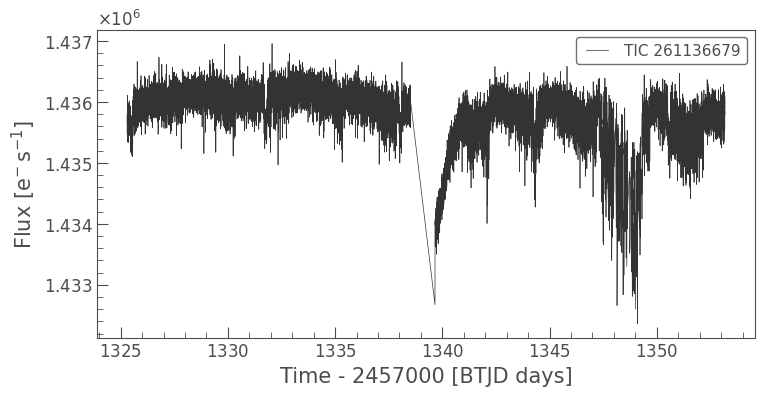

In [10]:
lc = tpf.to_lightcurve()

lc.plot()

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

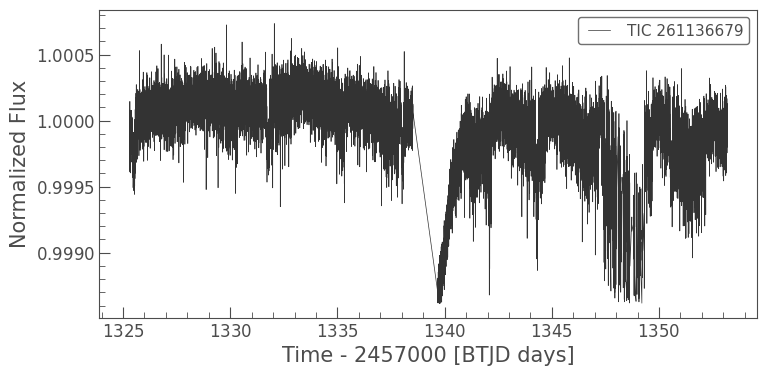

In [12]:
clean_lc = lc.remove_outliers()

clean_lc = clean_lc.normalize()

clean_lc.plot()

<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

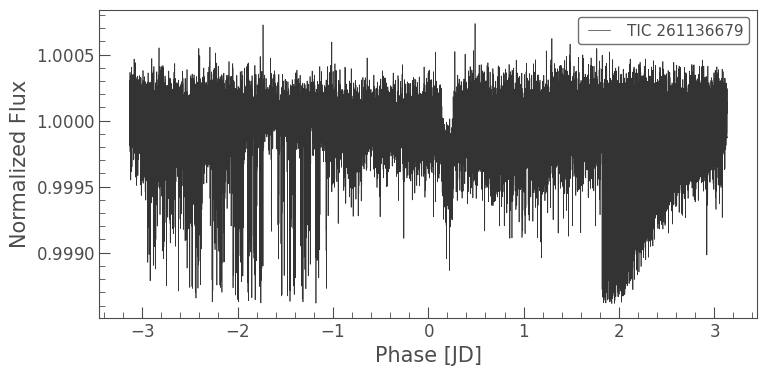

In [13]:
period = 6.27

folded_lc = clean_lc.fold(period=period)

folded_lc.plot()

<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

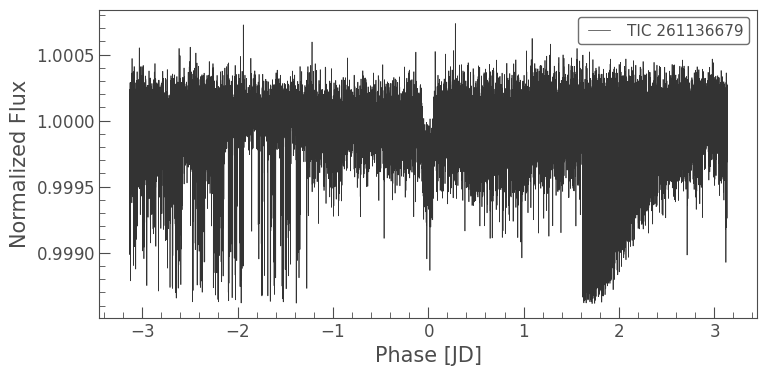

In [14]:
import astropy.units as u

folded_lc = clean_lc.fold(
    period=6.27,
    epoch_time=1325.504
)

folded_lc.plot()

<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

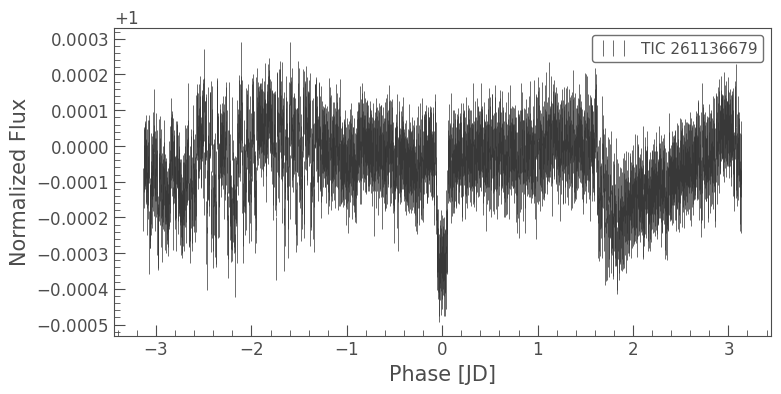

In [15]:
binned_lc = folded_lc.bin(
    time_bin_size=5*u.minute
)

binned_lc.errorbar()

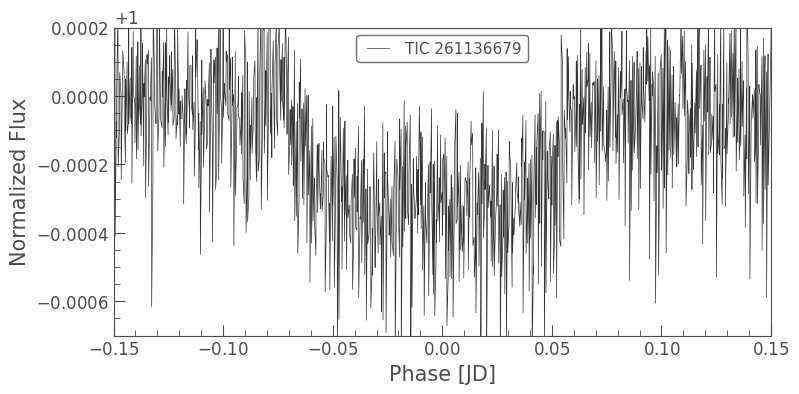

In [16]:
import matplotlib.pyplot as plt

ax = folded_lc.plot()

ax.set_xlim(-0.15, 0.15)
ax.set_ylim(0.9993, 1.0002)

plt.show()

In [18]:
import numpy as np

phase = folded_lc.time.value
flux = folded_lc.flux.value

# Select observations inside the transit
inside = np.abs(phase) < 0.04

# Select observations outside the transit
outside = (np.abs(phase) > 0.10) & (np.abs(phase) < 0.20)

# Calculate median brightness
F_in = np.nanmedian(flux[inside])
F_out = np.nanmedian(flux[outside])

# Calculate transit depth
depth = (F_out - F_in) / F_out

# Calculate radius ratio
radius_ratio = np.sqrt(depth)

print("In-transit flux:", F_in)
print("Out-of-transit flux:", F_out)
print("Transit depth:", depth)
print("Transit depth (ppm):", depth * 1e6)
print("Planet-to-star radius ratio:", radius_ratio)

In-transit flux: 0.9996821
Out-of-transit flux: 0.99998486
Transit depth: 0.00030273656
Transit depth (ppm): 302.73657
Planet-to-star radius ratio: 0.017399326


In [19]:
import numpy as np

print("Total observations:", len(folded_lc.flux))
print("In-transit observations:", np.sum(inside))
print("Out-of-transit observations:", np.sum(outside))

print("In-transit standard deviation:",
      np.nanstd(flux[inside]))

print("Out-of-transit standard deviation:",
      np.nanstd(flux[outside]))

Total observations: 18164
In-transit observations: 284
Out-of-transit observations: 714
In-transit standard deviation: 0.00016953817
Out-of-transit standard deviation: 0.00016920405


In [20]:
import numpy as np

n_in = np.sum(inside)
n_out = np.sum(outside)

sigma_in = np.nanstd(flux[inside])
sigma_out = np.nanstd(flux[outside])

error_in = sigma_in / np.sqrt(n_in)
error_out = sigma_out / np.sqrt(n_out)

depth_error = np.sqrt(error_in**2 + error_out**2)

print("Transit depth:", depth)
print("Estimated statistical uncertainty:", depth_error)
print("Uncertainty in ppm:", depth_error * 1e6)

Transit depth: 0.00030273656
Estimated statistical uncertainty: 1.1887239759820809e-05
Uncertainty in ppm: 11.887239759820808


In [21]:
import numpy as np

quality, counts = np.unique(tpf.quality, return_counts=True)

print("TESS quality flags:")
for q, count in zip(quality, counts):
    print(f"Flag {q}: {count} observations")

print("Total quality-flagged observations:",
      np.sum(tpf.quality != 0))

TESS quality flags:
Flag 0: 18264 observations
Total quality-flagged observations: 0


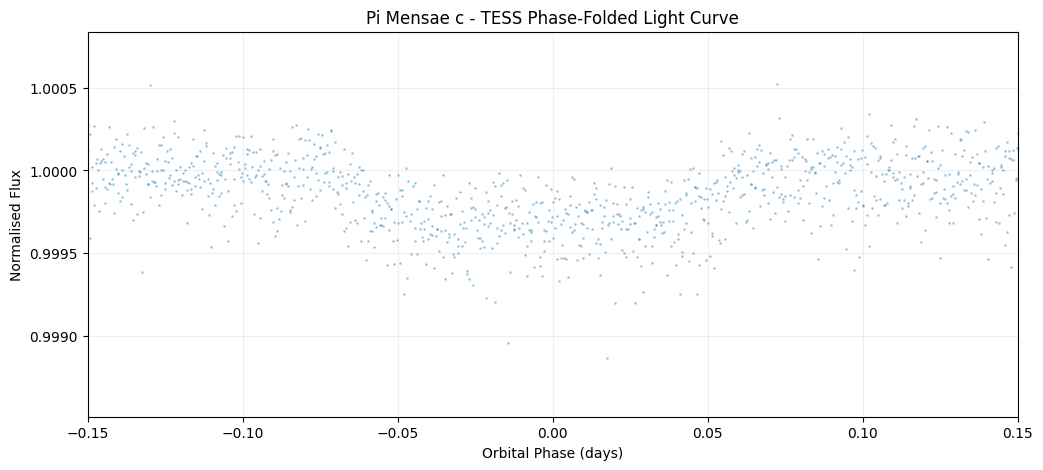

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.errorbar(
    folded_lc.time.value,
    folded_lc.flux.value,
    fmt='.',
    markersize=2,
    alpha=0.3
)

plt.xlim(-0.15, 0.15)
plt.xlabel("Orbital Phase (days)")
plt.ylabel("Normalised Flux")
plt.title("Pi Mensae c - TESS Phase-Folded Light Curve")

plt.grid(alpha=0.2)
plt.show()

<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

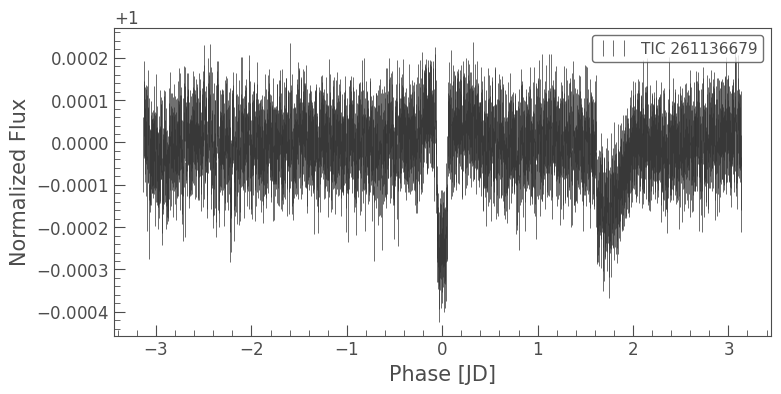

In [23]:
# Remove outliers using a 6-sigma threshold
clipped_lc = lc.remove_outliers(sigma=6)

# Flatten long-term instrumental and stellar trends
flat_lc = clipped_lc.flatten(window_length=1001)

# Remove the interval affected by instrumental noise
flat_lc = flat_lc[
    (flat_lc.time.value < 1346) |
    (flat_lc.time.value > 1350)
]

# Fold using the published planetary period and epoch
import astropy.units as u

folded_clean = flat_lc.fold(
    period=6.27,
    epoch_time=1325.504
)

# Bin observations into 5-minute intervals
binned_clean = folded_clean.bin(
    time_bin_size=5*u.minute
)

# Display the improved transit
binned_clean.errorbar()

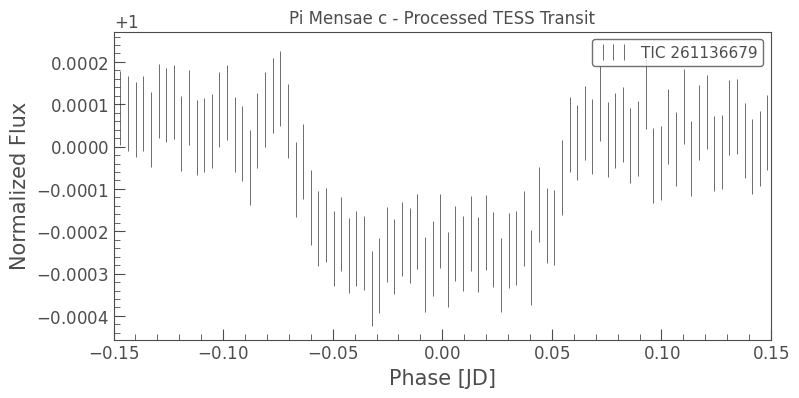

In [24]:
import lightkurve as lk
import astropy.units as u
import matplotlib.pyplot as plt

# Step 1: Extract brightness using TESS pipeline aperture
lc_research = tpf.to_lightcurve(
    aperture_mask=tpf.pipeline_mask
)

# Step 2: Remove long-term trends
flat_research = lc_research.flatten(
    window_length=1001
)

# Step 3: Exclude spacecraft jitter
mask = (
    (flat_research.time.value < 1346) |
    (flat_research.time.value > 1350)
)

masked_research = flat_research[mask]

# Step 4: Remove outliers
clean_research = masked_research.remove_outliers(
    sigma=6
)

# Step 5: Fold using published planetary parameters
folded_research = clean_research.fold(
    period=6.27,
    epoch_time=1325.504
)

# Step 6: Bin observations
binned_research = folded_research.bin(
    time_bin_size=5*u.minute
)

# Step 7: Plot
ax = binned_research.errorbar()
ax.set_xlim(-0.15, 0.15)
ax.set_title("Pi Mensae c - Processed TESS Transit")
plt.show()

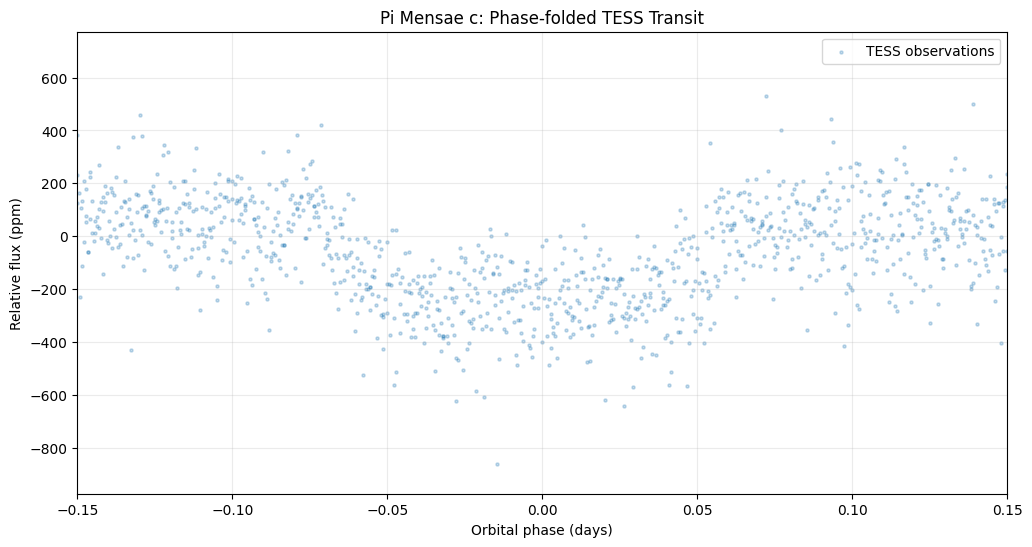

In [25]:
import matplotlib.pyplot as plt
import numpy as np

phase = folded_research.time.value
flux = folded_research.flux.value

plt.figure(figsize=(12, 6))

plt.scatter(
    phase,
    (flux - 1) * 1e6,
    s=5,
    alpha=0.25,
    label="TESS observations"
)

plt.xlabel("Orbital phase (days)")
plt.ylabel("Relative flux (ppm)")
plt.title("Pi Mensae c: Phase-folded TESS Transit")

plt.xlim(-0.15, 0.15)
plt.grid(alpha=0.25)
plt.legend()

plt.show()

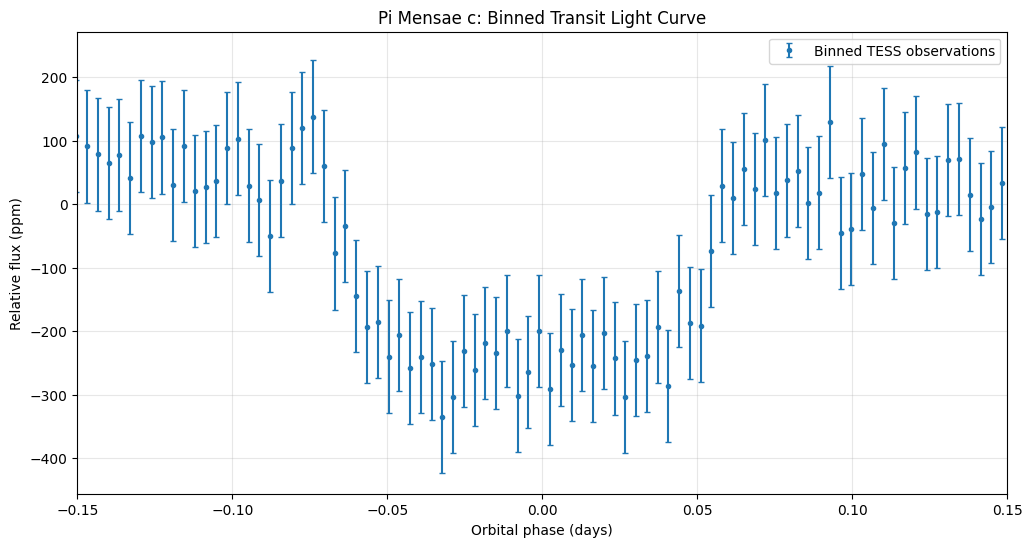

In [26]:
import matplotlib.pyplot as plt
import numpy as np

phase = binned_research.time.value
flux = binned_research.flux.value

plt.figure(figsize=(12, 6))

plt.errorbar(
    phase,
    (flux - 1) * 1e6,
    yerr=binned_research.flux_err.value * 1e6,
    fmt='o',
    markersize=3,
    capsize=2,
    label='Binned TESS observations'
)

plt.xlabel("Orbital phase (days)")
plt.ylabel("Relative flux (ppm)")
plt.title("Pi Mensae c: Binned Transit Light Curve")

plt.xlim(-0.15, 0.15)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [27]:
import numpy as np

phase = binned_research.time.value
flux = binned_research.flux.value

# Select transit observations
inside = np.abs(phase) < 0.045

# Select baseline observations
outside = (np.abs(phase) > 0.09) & (np.abs(phase) < 0.15)

# Calculate median flux
F_in = np.nanmedian(flux[inside])
F_out = np.nanmedian(flux[outside])

# Calculate transit depth
depth = (F_out - F_in) / F_out

# Convert to ppm
depth_ppm = depth * 1e6

# Estimate radius ratio
radius_ratio = np.sqrt(depth)

print("In-transit flux:", F_in)
print("Out-of-transit flux:", F_out)
print("Transit depth:", depth)
print("Transit depth (ppm):", depth_ppm)
print("Planet-to-star radius ratio:", radius_ratio)

In-transit flux: 0.9997556450895136
Out-of-transit flux: 1.0000444821455892
Transit depth: 0.00028882420855502473
Transit depth (ppm): 288.8242085550247
Planet-to-star radius ratio: 0.01699482887689737


In [28]:
import numpy as np

phase = binned_research.time.value
flux = binned_research.flux.value

# Define our selected regions
inside = np.abs(phase) < 0.045
outside = (np.abs(phase) > 0.09) & (np.abs(phase) < 0.15)

in_data = flux[inside]
out_data = flux[outside]

# Bootstrap resampling
rng = np.random.default_rng(42)

depth_samples = []

for i in range(5000):
    in_sample = rng.choice(in_data, len(in_data), replace=True)
    out_sample = rng.choice(out_data, len(out_data), replace=True)

    F_in = np.median(in_sample)
    F_out = np.median(out_sample)

    depth_samples.append((F_out - F_in) / F_out)

depth_samples = np.array(depth_samples)

# Calculate uncertainty
depth_mean = np.median(depth_samples)
uncertainty = np.std(depth_samples)

print("Bootstrap transit depth:", depth_mean * 1e6, "ppm")
print("Bootstrap uncertainty:", uncertainty * 1e6, "ppm")
print("Lower 95% limit:", np.percentile(depth_samples, 2.5) * 1e6)
print("Upper 95% limit:", np.percentile(depth_samples, 97.5) * 1e6)

Bootstrap transit depth: 290.9341320353974 ppm
Bootstrap uncertainty: 16.373136219865607 ppm
Lower 95% limit: 265.0279803709523
Upper 95% limit: 324.3294629760636


In [29]:
import numpy as np

radius_ratio = np.sqrt(depth_mean)

print("Updated radius ratio:", radius_ratio)
print("Planet radius as percentage of star:",
      radius_ratio * 100)

Updated radius ratio: 0.01705679137573645
Planet radius as percentage of star: 1.705679137573645


In [30]:
# Published stellar radius
stellar_radius = 1.10  # Solar radii

# Convert solar radii to Earth radii
solar_to_earth = 109.076

# Calculate approximate planetary radius
planet_radius = (
    radius_ratio * stellar_radius * solar_to_earth
)

print("Estimated planetary radius:",
      planet_radius, "Earth radii")

Estimated planetary radius: 2.046535233709812 Earth radii


In [31]:
import numpy as np

# Uncertainty in radius ratio
radius_ratio_error = uncertainty / (2 * np.sqrt(depth_mean))

# Published stellar radius uncertainty
stellar_radius_error = 0.01

# Calculate planetary radius uncertainty
planet_radius_error = planet_radius * np.sqrt(
    (radius_ratio_error / radius_ratio)**2 +
    (stellar_radius_error / stellar_radius)**2
)

print("Planetary radius:", planet_radius, "Earth radii")
print("Radius uncertainty:", planet_radius_error, "Earth radii")

Planetary radius: 2.046535233709812 Earth radii
Radius uncertainty: 0.06051804501318335 Earth radii


In [32]:
!pip install batman-package

In [33]:
import batman
import numpy as np
import matplotlib.pyplot as plt

print("Batman transit modelling package is ready!")

Batman transit modelling package is ready!


In [34]:
params = batman.TransitParams()

params.t0 = 1325.504
params.per = 6.27
params.rp = radius_ratio
params.a = 15.0
params.inc = 88.0
params.ecc = 0.0
params.w = 90.0
params.u = [0.3, 0.2]
params.limb_dark = "quadratic"

print("Transit model parameters prepared.")

Transit model parameters prepared.


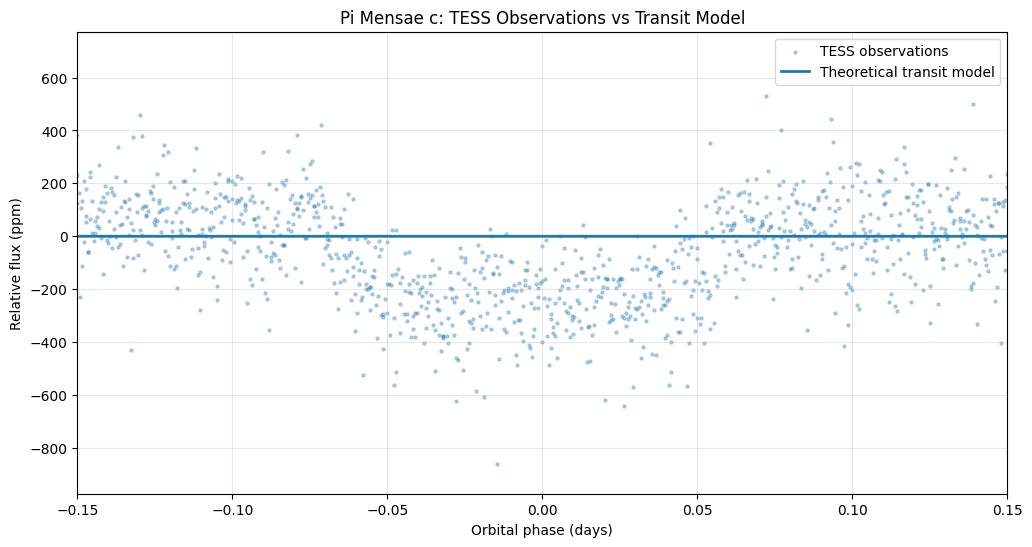

In [35]:
import batman
import numpy as np
import matplotlib.pyplot as plt

# Use phase-folded observations
time = folded_research.time.value
flux = folded_research.flux.value

# Create transit model
model = batman.TransitModel(params, time)

# Calculate theoretical brightness
model_flux = model.light_curve(params)

# Plot observations and theoretical model
plt.figure(figsize=(12, 6))

plt.scatter(
    time,
    (flux - 1) * 1e6,
    s=5,
    alpha=0.3,
    label="TESS observations"
)

plt.plot(
    time,
    (model_flux - 1) * 1e6,
    linewidth=2,
    label="Theoretical transit model"
)

plt.xlabel("Orbital phase (days)")
plt.ylabel("Relative flux (ppm)")
plt.title("Pi Mensae c: TESS Observations vs Transit Model")

plt.xlim(-0.15, 0.15)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

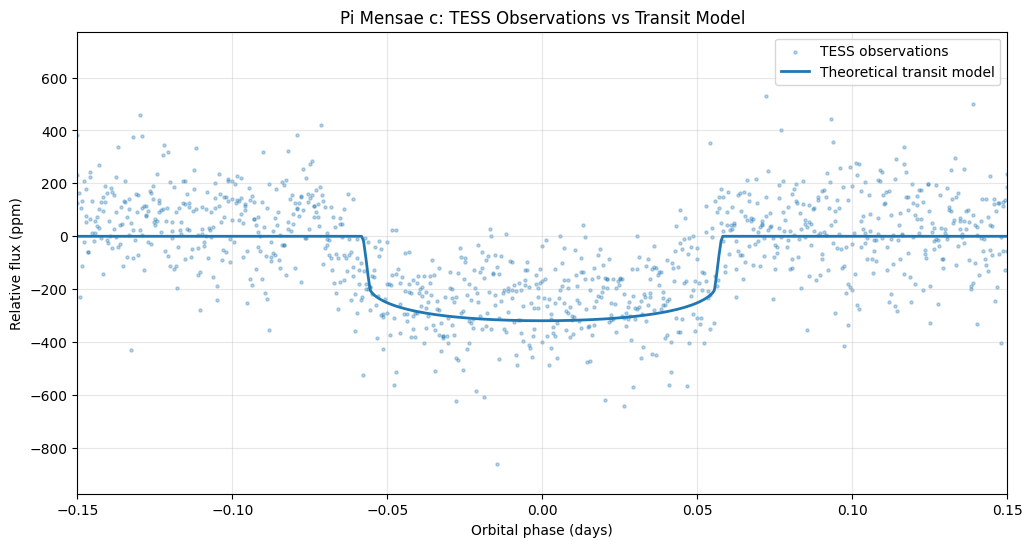

In [36]:
import batman
import numpy as np
import matplotlib.pyplot as plt

# Use phase-folded observations
time = folded_research.time.value
flux = folded_research.flux.value

# Correct the reference time
params.t0 = 0.0

# Generate theoretical model
model = batman.TransitModel(params, time)
model_flux = model.light_curve(params)

# Plot observations and model
plt.figure(figsize=(12, 6))

plt.scatter(
    time,
    (flux - 1) * 1e6,
    s=5,
    alpha=0.3,
    label="TESS observations"
)

plt.plot(
    time,
    (model_flux - 1) * 1e6,
    linewidth=2,
    label="Theoretical transit model"
)

plt.xlabel("Orbital phase (days)")
plt.ylabel("Relative flux (ppm)")
plt.title("Pi Mensae c: TESS Observations vs Transit Model")

plt.xlim(-0.15, 0.15)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [37]:
from scipy.optimize import curve_fit

def transit_model(time, rp):
    params.rp = rp
    model = batman.TransitModel(params, time)
    return model.light_curve(params)

# Fit the radius ratio
popt, pcov = curve_fit(
    transit_model,
    time,
    flux,
    p0=[radius_ratio]
)

best_radius_ratio = popt[0]
radius_error = np.sqrt(pcov[0, 0])

print("Best-fitting radius ratio:", best_radius_ratio)
print("Estimated fitting uncertainty:", radius_error)
print("Fitted transit depth (ppm):",
      best_radius_ratio**2 * 1e6)

Best-fitting radius ratio: 0.015222515625340384
Estimated fitting uncertainty: 0.00024797784446535374
Fitted transit depth (ppm): 231.72498196373218


In [38]:
best_planet_radius = (
    best_radius_ratio * stellar_radius * solar_to_earth
)

print("Fitted planetary radius:",
      best_planet_radius, "Earth radii")

Fitted planetary radius: 1.8264522257845908 Earth radii


In [39]:
from scipy.optimize import curve_fit
import numpy as np

# Use binned observations
time_fit = binned_research.time.value
flux_fit = binned_research.flux.value
error_fit = binned_research.flux_err.value

# Transit model
def transit_model(time, rp):
    params.rp = rp
    model = batman.TransitModel(params, time)
    return model.light_curve(params)

# Weighted fitting
popt, pcov = curve_fit(
    transit_model,
    time_fit,
    flux_fit,
    p0=[best_radius_ratio],
    sigma=error_fit,
    absolute_sigma=True,
    maxfev=10000
)

fitted_rp = popt[0]
fitted_error = np.sqrt(pcov[0, 0])

print("Weighted radius ratio:", fitted_rp)
print("Radius ratio uncertainty:", fitted_error)
print("Transit depth (ppm):", fitted_rp**2 * 1e6)

Weighted radius ratio: 0.015232647920554745
Radius ratio uncertainty: 0.0005030506132504552
Transit depth (ppm): 232.0335626715808


In [40]:
from scipy.optimize import curve_fit
import numpy as np
import batman

time_fit = binned_research.time.value
flux_fit = binned_research.flux.value
error_fit = binned_research.flux_err.value

def improved_model(time, rp, t0, a, inc):

    params.rp = rp
    params.t0 = t0
    params.a = a
    params.inc = inc

    model = batman.TransitModel(params, time)

    return model.light_curve(params)

p0 = [0.0172, 0.0, 15.0, 88.0]

bounds = (
    [0.005, -0.02, 5.0, 80.0],
    [0.04, 0.02, 30.0, 90.0]
)

popt, pcov = curve_fit(
    improved_model,
    time_fit,
    flux_fit,
    p0=p0,
    sigma=error_fit,
    absolute_sigma=True,
    bounds=bounds,
    maxfev=20000
)

errors = np.sqrt(np.diag(pcov))

print("Fitted radius ratio:", popt[0])
print("Fitted transit time:", popt[1])
print("Fitted scaled separation:", popt[2])
print("Fitted inclination:", popt[3])

print("Parameter uncertainties:", errors)
print("Fitted transit depth (ppm):", popt[0]**2 * 1e6)

Fitted radius ratio: 0.014876746307133842
Fitted transit time: -0.003070214076786415
Fitted scaled separation: 17.320268285203454
Fitted inclination: 89.95940178716864
Parameter uncertainties: [1.11839681e-02 2.74517793e-03 8.37399189e+01 1.29971779e+03]
Fitted transit depth (ppm): 221.3175806868204


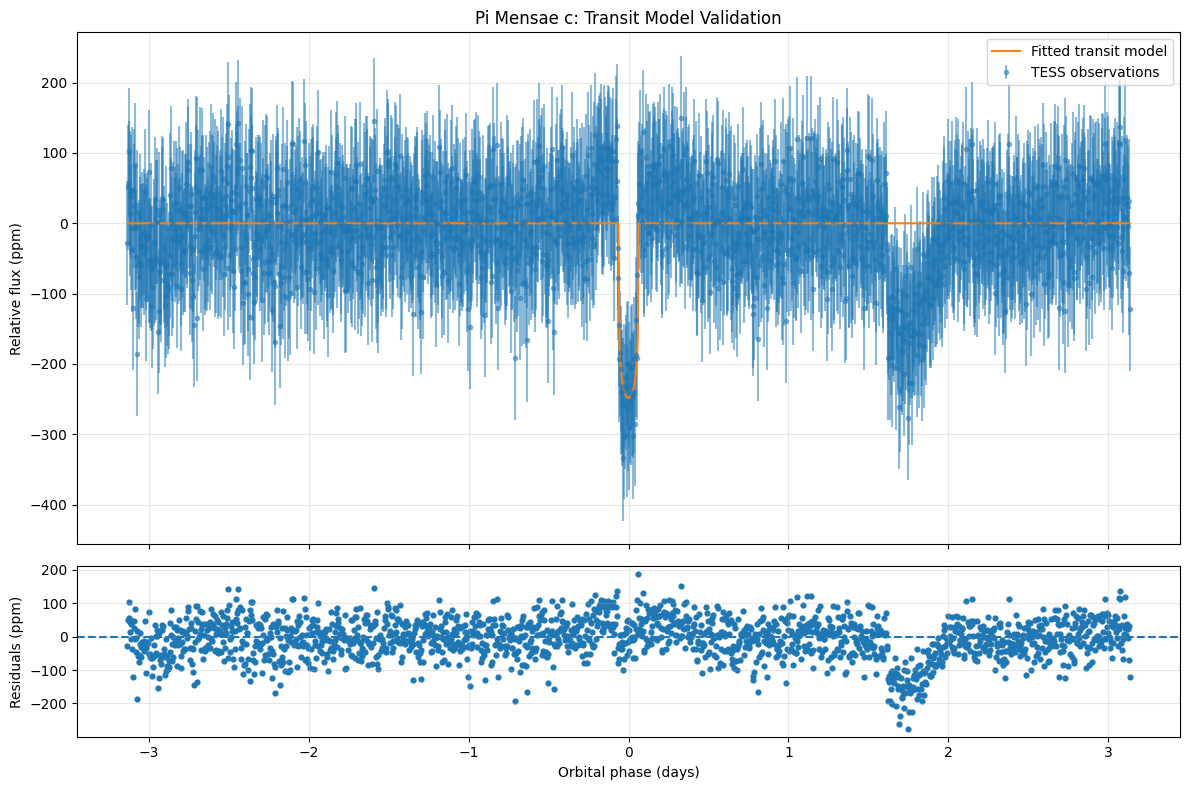

In [42]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate fitted model
fitted_flux = constrained_model(time_fit, fitted_rp)

# Calculate residuals
residuals = (flux_fit - fitted_flux) * 1e6

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
)

# Observations and model
ax1.errorbar(
    time_fit,
    (flux_fit - 1) * 1e6,
    yerr=error_fit * 1e6,
    fmt='.',
    alpha=0.5,
    label='TESS observations'
)

ax1.plot(
    time_fit,
    (fitted_flux - 1) * 1e6,
    label='Fitted transit model'
)

ax1.set_ylabel('Relative flux (ppm)')
ax1.set_title('Pi Mensae c: Transit Model Validation')
ax1.legend()
ax1.grid(alpha=0.3)

# Residual plot
ax2.scatter(time_fit, residuals, s=12)
ax2.axhline(0, linestyle='--')
ax2.set_xlabel('Orbital phase (days)')
ax2.set_ylabel('Residuals (ppm)')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

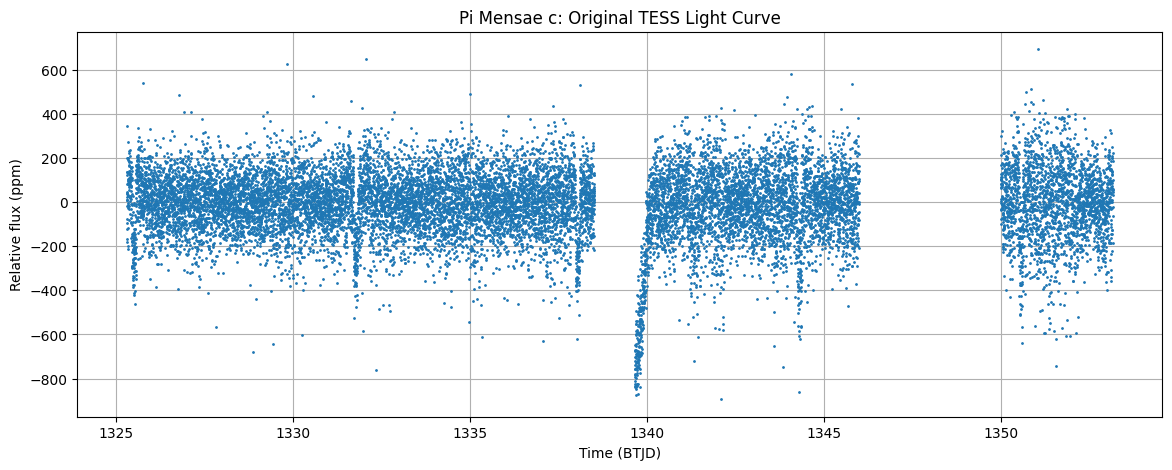

In [43]:
plt.figure(figsize=(14, 5))

plt.plot(
    clean_research.time.value,
    (clean_research.flux.value - 1) * 1e6,
    '.',
    markersize=2
)

plt.xlabel("Time (BTJD)")
plt.ylabel("Relative flux (ppm)")
plt.title("Pi Mensae c: Original TESS Light Curve")
plt.grid(True)
plt.show()

In [44]:
import numpy as np

period = 6.26834
epoch = 1325.504

predicted_times = epoch + period * np.arange(0, 6)

print("Predicted transit times (BTJD):")
for t in predicted_times:
    print(round(t, 5))

print("\nObserved data nearest each predicted transit:")
for t in predicted_times:
    nearest_index = np.argmin(
        np.abs(clean_research.time.value - t)
    )
    observed_time = clean_research.time.value[nearest_index]
    observed_flux = clean_research.flux.value[nearest_index]

    print(
        f"Predicted: {t:.5f}, "
        f"Nearest observation: {observed_time:.5f}, "
        f"Relative flux: {(observed_flux - 1)*1e6:.1f} ppm"
    )

Predicted transit times (BTJD):
1325.504
1331.77234
1338.04068
1344.30902
1350.57736
1356.8457

Observed data nearest each predicted transit:
Predicted: 1325.50400, Nearest observation: 1325.50390, Relative flux: -170.8 ppm
Predicted: 1331.77234, Nearest observation: 1331.77188, Relative flux: -148.2 ppm
Predicted: 1338.04068, Nearest observation: 1338.04123, Relative flux: -352.3 ppm
Predicted: 1344.30902, Nearest observation: 1344.30918, Relative flux: -128.3 ppm
Predicted: 1350.57736, Nearest observation: 1350.57712, Relative flux: -203.1 ppm
Predicted: 1356.84570, Nearest observation: 1353.17707, Relative flux: 55.3 ppm


In [45]:
import numpy as np

times = clean_research.time.value
flux = clean_research.flux.value

period = 6.26834
epoch = 1325.504

print("Transit-window analysis\n")

for n in range(5):
    t0 = epoch + n * period

    # Observations within 2 hours of predicted transit
    inside = np.abs(times - t0) < (2 / 24)

    # Nearby baseline observations, 4–8 hours from transit
    outside = (
        (np.abs(times - t0) > (4 / 24)) &
        (np.abs(times - t0) < (8 / 24))
    )

    if inside.sum() > 0 and outside.sum() > 0:
        transit_flux = np.median(flux[inside])
        baseline_flux = np.median(flux[outside])

        depth = (baseline_flux - transit_flux) * 1e6

        print(f"Transit {n+1}: BTJD {t0:.5f}")
        print(f"Observations inside: {inside.sum()}")
        print(f"Median transit flux: {transit_flux:.7f}")
        print(f"Median baseline flux: {baseline_flux:.7f}")
        print(f"Estimated depth: {depth:.2f} ppm\n")
    else:
        print(f"Transit {n+1}: insufficient observations\n")

Transit-window analysis

Transit 1: BTJD 1325.50400
Observations inside: 120
Median transit flux: 0.9998430
Median baseline flux: 1.0000415
Estimated depth: 198.50 ppm

Transit 2: BTJD 1331.77234
Observations inside: 119
Median transit flux: 0.9998371
Median baseline flux: 1.0000737
Estimated depth: 236.55 ppm

Transit 3: BTJD 1338.04068
Observations inside: 120
Median transit flux: 0.9998210
Median baseline flux: 1.0000202
Estimated depth: 199.14 ppm

Transit 4: BTJD 1344.30902
Observations inside: 114
Median transit flux: 0.9998228
Median baseline flux: 1.0000337
Estimated depth: 210.93 ppm

Transit 5: BTJD 1350.57736
Observations inside: 120
Median transit flux: 0.9998680
Median baseline flux: 1.0000173
Estimated depth: 149.32 ppm



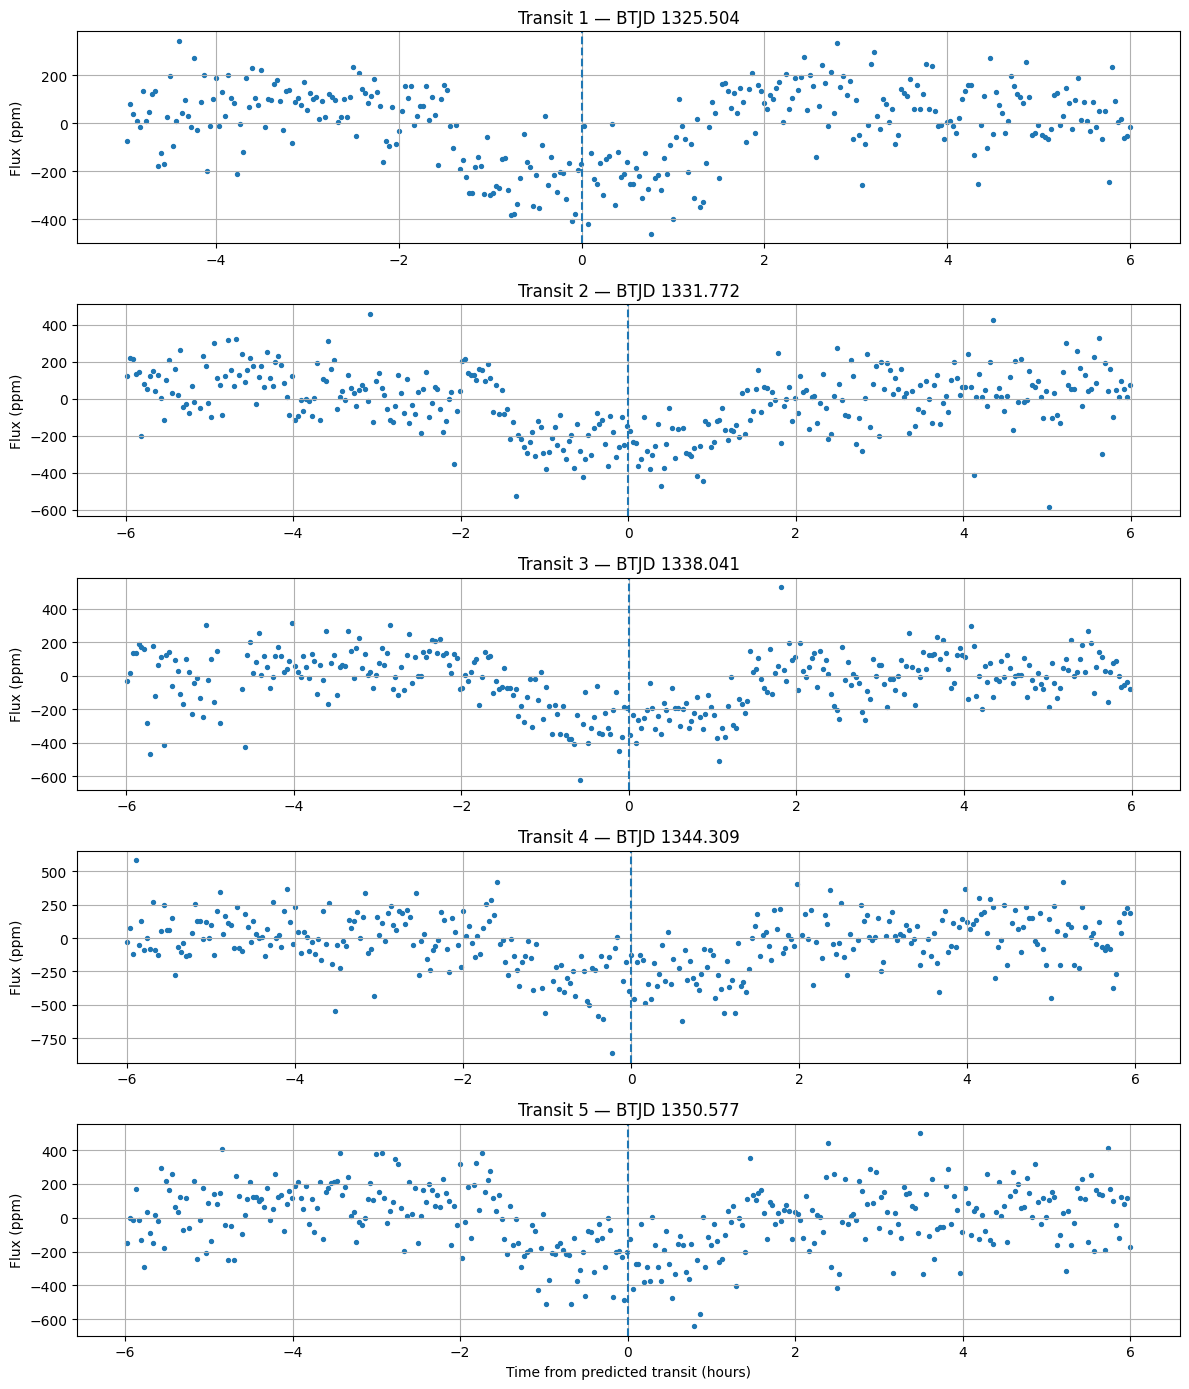

In [46]:
import matplotlib.pyplot as plt
import numpy as np

period = 6.26834
epoch = 1325.504

times = clean_research.time.value
flux = clean_research.flux.value

fig, axes = plt.subplots(5, 1, figsize=(12, 14))

for n, ax in enumerate(axes):
    t0 = epoch + n * period

    # Show observations within 6 hours of each predicted transit
    mask = np.abs(times - t0) < (6 / 24)

    relative_hours = (times[mask] - t0) * 24

    ax.scatter(
        relative_hours,
        (flux[mask] - 1) * 1e6,
        s=8
    )

    ax.axvline(0, linestyle="--")
    ax.set_title(f"Transit {n+1} — BTJD {t0:.3f}")
    ax.set_ylabel("Flux (ppm)")
    ax.grid(True)

axes[-1].set_xlabel("Time from predicted transit (hours)")

plt.tight_layout()
plt.show()

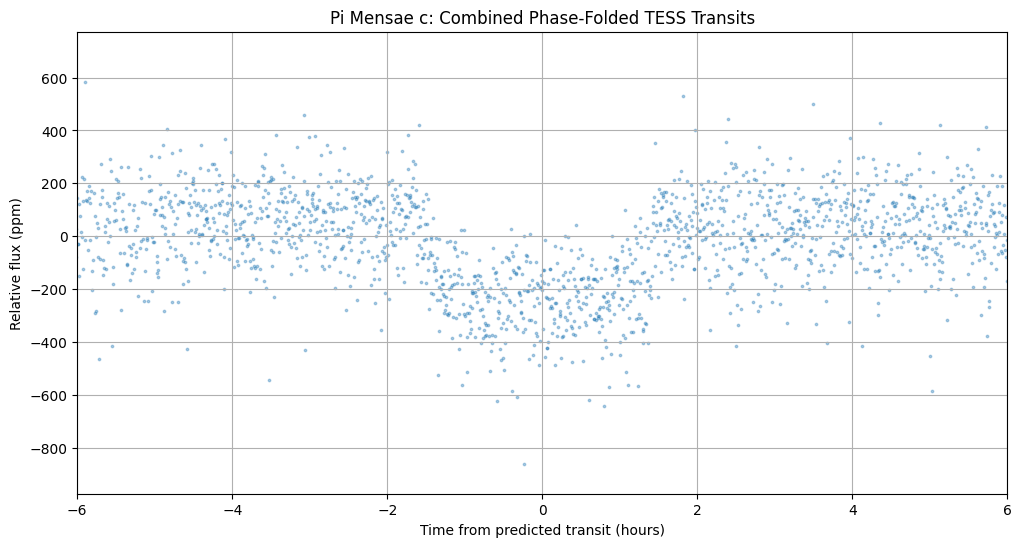

In [47]:
import lightkurve as lk
import matplotlib.pyplot as plt

period = 6.26834
epoch = 1325.504

folded = clean_research.fold(
    period=period,
    epoch_time=epoch
)

plt.figure(figsize=(12, 6))

plt.scatter(
    folded.time.value * 24,
    (folded.flux.value - 1) * 1e6,
    s=3,
    alpha=0.35
)

plt.xlim(-6, 6)
plt.xlabel("Time from predicted transit (hours)")
plt.ylabel("Relative flux (ppm)")
plt.title("Pi Mensae c: Combined Phase-Folded TESS Transits")
plt.grid(True)
plt.show()

In [48]:
import lightkurve as lk
import matplotlib.pyplot as plt

lc_result = lk.search_lightcurve(
    "Pi Mensae",
    mission="TESS",
    sector=1,
    author="SPOC"
)

print(lc_result)

SearchResult containing 1 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 01 2018   SPOC     120   261136679      0.0


In [49]:
pipeline_lc = lc_result.download()

print(pipeline_lc)

       time             flux      ...   pos_corr1      pos_corr2   
                    electron / s  ...      pix            pix      
------------------ -------------- ... -------------- --------------
1325.2969604950604  1.4641956e+06 ...  9.0913408e-02 -7.2966635e-02
1325.2983493645327  1.4643365e+06 ...  6.2022530e-02 -1.0871942e-01
 1325.299738234005  1.4643485e+06 ...  6.1673984e-02 -1.1394957e-01
 1325.301127103477  1.4643674e+06 ...  6.0909923e-02 -1.2573890e-01
1325.3025159730657  1.4642560e+06 ...  5.3837594e-02 -1.2532526e-01
 1325.303904842538  1.4644681e+06 ...  5.2977830e-02 -1.2562653e-01
1325.3052937121265  1.4643586e+06 ...  5.7222184e-02 -1.3051888e-01
1325.3066825815986  1.4643564e+06 ...  5.5443291e-02 -1.2712292e-01
1325.3080714511873  1.4645452e+06 ...  5.1877767e-02 -1.2947108e-01
               ...            ... ...            ...            ...
1353.1645661947705  1.4646795e+06 ...  5.5579260e-02 -1.1038263e-02
1353.1659550506233  1.4649392e+06 ...  6.0031198

In [50]:
print(pipeline_lc.colnames)

['time', 'flux', 'flux_err', 'timecorr', 'cadenceno', 'centroid_col', 'centroid_row', 'sap_flux', 'sap_flux_err', 'sap_bkg', 'sap_bkg_err', 'pdcsap_flux', 'pdcsap_flux_err', 'quality', 'psf_centr1', 'psf_centr1_err', 'psf_centr2', 'psf_centr2_err', 'mom_centr1', 'mom_centr1_err', 'mom_centr2', 'mom_centr2_err', 'pos_corr1', 'pos_corr2']


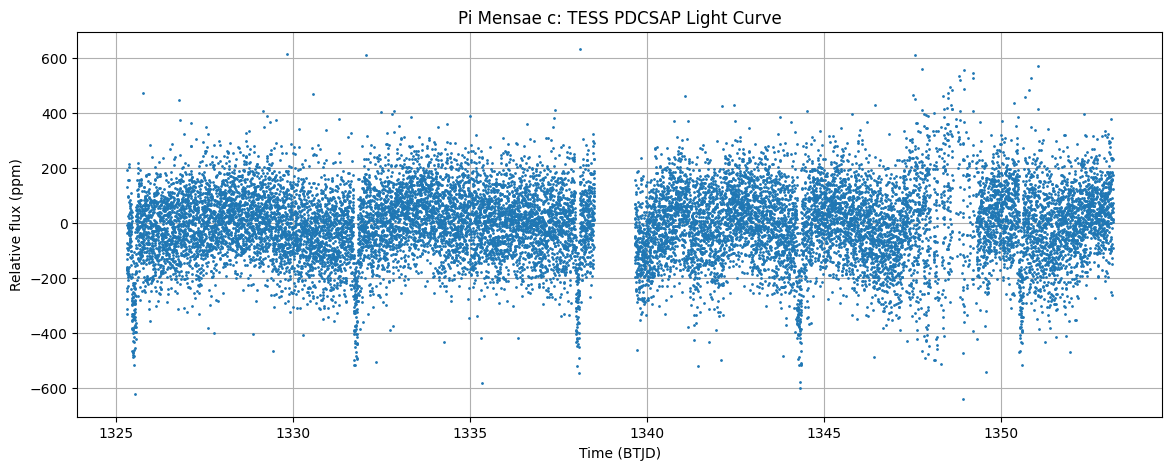

In [51]:
# Extract pipeline-corrected flux
pdcsap_lc = pipeline_lc.select_flux("pdcsap_flux")

# Remove invalid measurements and normalise
pdcsap_clean = pdcsap_lc.remove_nans()
pdcsap_clean = pdcsap_clean.remove_outliers(sigma=5)
pdcsap_clean = pdcsap_clean.normalize()

# Plot the corrected light curve
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    pdcsap_clean.time.value,
    (pdcsap_clean.flux.value - 1) * 1e6,
    '.',
    markersize=2
)

plt.xlabel("Time (BTJD)")
plt.ylabel("Relative flux (ppm)")
plt.title("Pi Mensae c: TESS PDCSAP Light Curve")
plt.grid(True)
plt.show()

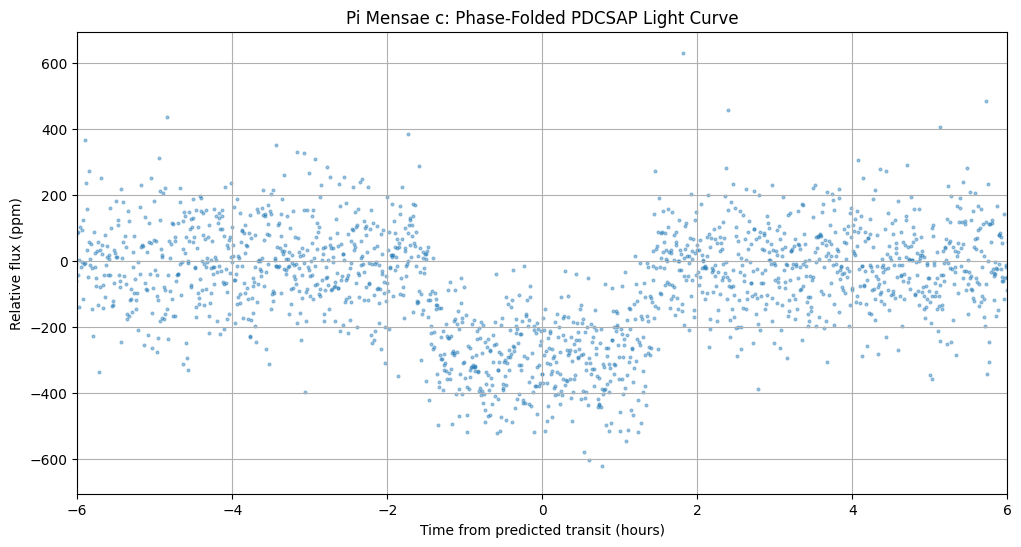

In [52]:
period = 6.26834
epoch = 1325.504

pdcsap_folded = pdcsap_clean.fold(
    period=period,
    epoch_time=epoch
)

plt.figure(figsize=(12, 6))

plt.scatter(
    pdcsap_folded.time.value * 24,
    (pdcsap_folded.flux.value - 1) * 1e6,
    s=4,
    alpha=0.4
)

plt.xlim(-6, 6)
plt.xlabel("Time from predicted transit (hours)")
plt.ylabel("Relative flux (ppm)")
plt.title("Pi Mensae c: Phase-Folded PDCSAP Light Curve")
plt.grid(True)
plt.show()

TypeError: cannot write to unmasked output

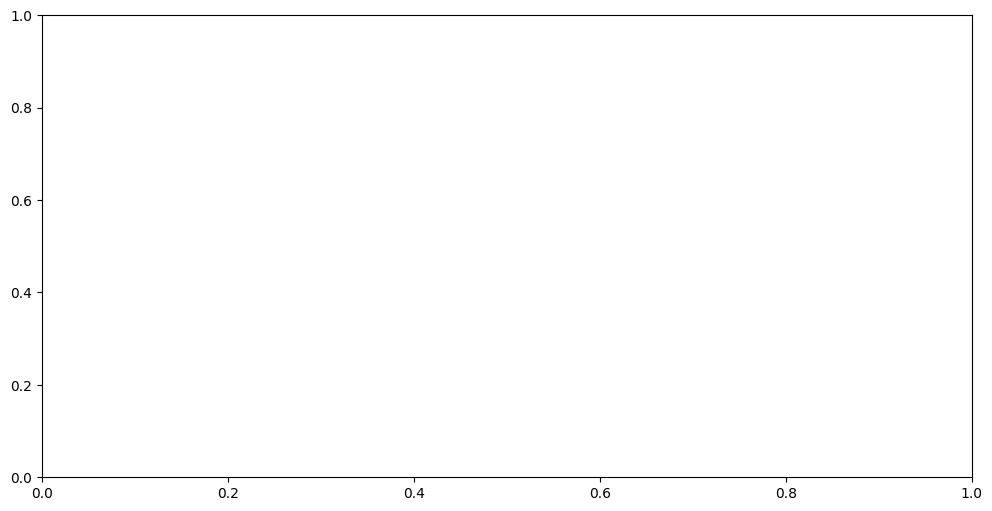

In [53]:
import astropy.units as u
import matplotlib.pyplot as plt

# Bin the phase-folded PDCSAP light curve into 5-minute intervals
pdcsap_binned = pdcsap_folded.bin(
    time_bin_size=5 * u.minute
)

plt.figure(figsize=(12, 6))

plt.errorbar(
    pdcsap_binned.time.value * 24,
    (pdcsap_binned.flux.value - 1) * 1e6,
    yerr=pdcsap_binned.flux_err.value * 1e6,
    fmt='.',
    markersize=5,
    capsize=2
)

plt.xlim(-5, 5)
plt.xlabel("Time from predicted transit (hours)")
plt.ylabel("Relative flux (ppm)")
plt.title("Pi Mensae c: Binned PDCSAP Transit Profile")
plt.grid(True)
plt.show()

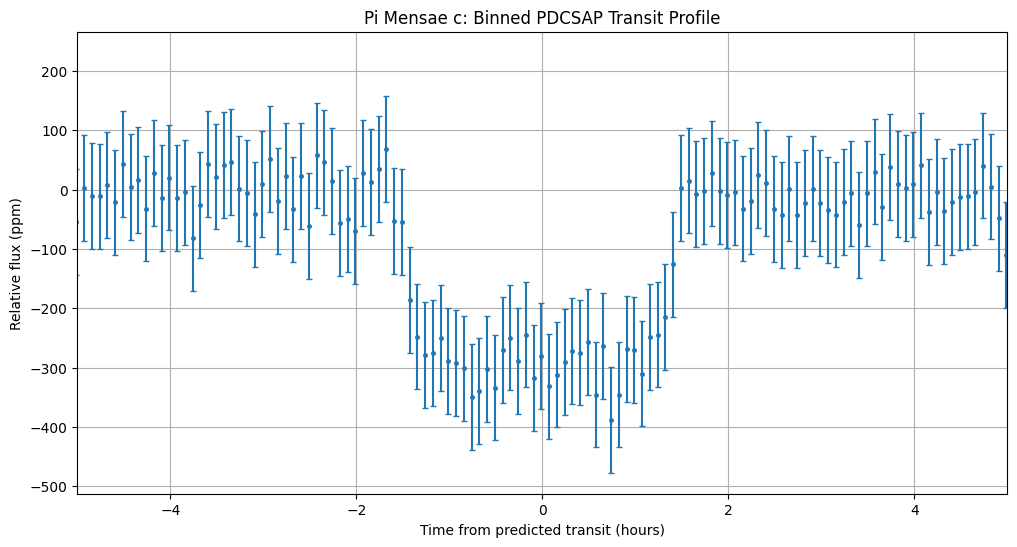

In [54]:
import numpy as np
import matplotlib.pyplot as plt

x = np.asarray(pdcsap_binned.time.value * 24)
y = np.asarray(pdcsap_binned.flux.value)
yerr = np.asarray(pdcsap_binned.flux_err.value)

# Keep only valid, unmasked values
valid = (
    np.isfinite(x) &
    np.isfinite(y) &
    np.isfinite(yerr)
)

plt.figure(figsize=(12, 6))

plt.errorbar(
    x[valid],
    (y[valid] - 1) * 1e6,
    yerr=yerr[valid] * 1e6,
    fmt='.',
    markersize=5,
    capsize=2
)

plt.xlim(-5, 5)
plt.xlabel("Time from predicted transit (hours)")
plt.ylabel("Relative flux (ppm)")
plt.title("Pi Mensae c: Binned PDCSAP Transit Profile")
plt.grid(True)
plt.show()

In [55]:
import numpy as np

phase_hours = pdcsap_binned.time.value * 24
flux = pdcsap_binned.flux.value

valid = np.isfinite(phase_hours) & np.isfinite(flux)

phase_hours = phase_hours[valid]
flux = flux[valid]

# Transit region
inside = np.abs(phase_hours) < 1.25

# Out-of-transit baseline
outside = (
    (np.abs(phase_hours) > 2.0) &
    (np.abs(phase_hours) < 5.0)
)

F_in = np.median(flux[inside])
F_out = np.median(flux[outside])

depth = (F_out - F_in) / F_out
radius_ratio = np.sqrt(depth)

print("PDCSAP Transit Analysis")
print("----------------------")
print(f"Median transit flux: {F_in:.8f}")
print(f"Median baseline flux: {F_out:.8f}")
print(f"Transit depth: {depth * 1e6:.2f} ppm")
print(f"Radius ratio (Rp/R*): {radius_ratio:.6f}")
print(f"Transit observations: {inside.sum()}")
print(f"Baseline observations: {outside.sum()}")

PDCSAP Transit Analysis
----------------------
Median transit flux: 0.99971092
Median baseline flux: 0.99999392
Transit depth: 283.00 ppm
Radius ratio (Rp/R*): 0.016823
Transit observations: 30
Baseline observations: 72


In [56]:
import batman
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Prepare PDCSAP binned data
t = np.asarray(pdcsap_binned.time.value)
f = np.asarray(pdcsap_binned.flux.value)
err = np.asarray(pdcsap_binned.flux_err.value)

valid = (
    np.isfinite(t) &
    np.isfinite(f) &
    np.isfinite(err) &
    (err > 0)
)

t, f, err = t[valid], f[valid], err[valid]

# Set up transit model
params = batman.TransitParams()
params.t0 = 0.0
params.per = 6.26834
params.rp = 0.01721
params.a = 13.10
params.inc = 87.31
params.ecc = 0.0
params.w = 90.0
params.u = [0.264, 0.309]
params.limb_dark = "quadratic"

def transit_model(time, rp):
    params.rp = rp
    model = batman.TransitModel(params, time)
    return model.light_curve(params)

# Fit radius ratio
popt, pcov = curve_fit(
    transit_model,
    t,
    f,
    p0=[0.01721],
    sigma=err,
    absolute_sigma=True,
    bounds=([0.005], [0.05]),
    maxfev=10000
)

rp_fit = popt[0]
rp_error = np.sqrt(pcov[0, 0])

print("TRANSIT MODEL FIT")
print("-----------------")
print(f"Radius ratio (Rp/R*): {rp_fit:.6f}")
print(f"Formal uncertainty: ±{rp_error:.6f}")
print(f"Transit depth: {rp_fit**2 * 1e6:.2f} ppm")

TRANSIT MODEL FIT
-----------------
Radius ratio (Rp/R*): 0.016977
Formal uncertainty: ±0.000452
Transit depth: 288.23 ppm


MODEL VALIDATION
----------------
Data points: 1806
Reduced chi-square: 0.236
Residual RMS: 43.21 ppm


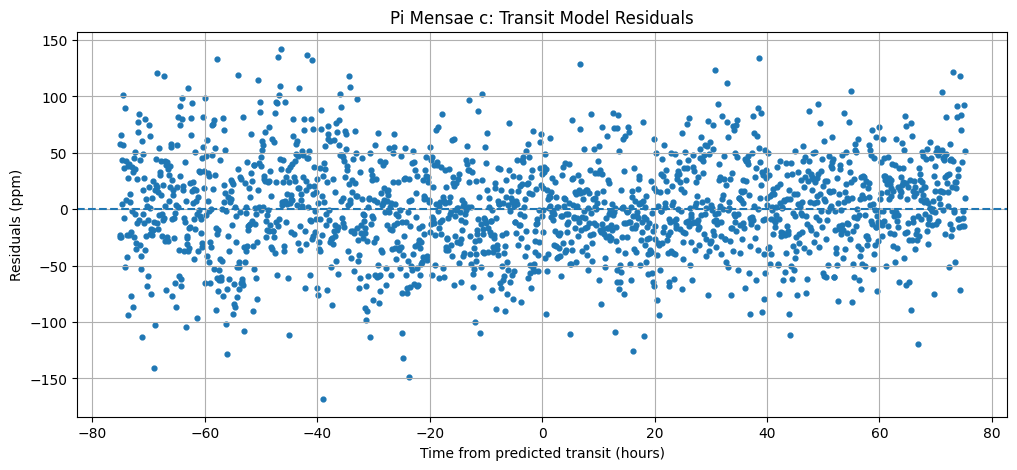

In [57]:
# Calculate fitted model and residuals
fitted_flux = transit_model(t, rp_fit)
residuals = (f - fitted_flux) * 1e6

# Calculate fit statistics
chi_squared = np.sum(((f - fitted_flux) / err)**2)
dof = len(f) - 1
reduced_chi_squared = chi_squared / dof

print("MODEL VALIDATION")
print("----------------")
print(f"Data points: {len(f)}")
print(f"Reduced chi-square: {reduced_chi_squared:.3f}")
print(f"Residual RMS: {np.std(residuals):.2f} ppm")

# Plot residuals
plt.figure(figsize=(12, 5))
plt.scatter(t * 24, residuals, s=12)
plt.axhline(0, linestyle="--")
plt.xlabel("Time from predicted transit (hours)")
plt.ylabel("Residuals (ppm)")
plt.title("Pi Mensae c: Transit Model Residuals")
plt.grid(True)
plt.show()

In [58]:
# Stellar radius from published literature
stellar_radius = 1.10
stellar_error = 0.01

# Solar radius to Earth radius conversion
solar_to_earth = 109.076

# Calculate planetary radius
planet_radius = rp_fit * stellar_radius * solar_to_earth

# Propagate formal uncertainties
planet_error = planet_radius * np.sqrt(
    (rp_error / rp_fit)**2 +
    (stellar_error / stellar_radius)**2
)

print("PI MENSAE c — PLANETARY RADIUS")
print("--------------------------------")
print(f"Planetary radius: {planet_radius:.3f} Earth radii")
print(f"Formal uncertainty: ±{planet_error:.3f} Earth radii")

PI MENSAE c — PLANETARY RADIUS
--------------------------------
Planetary radius: 2.037 Earth radii
Formal uncertainty: ±0.057 Earth radii


In [59]:
from scipy.optimize import curve_fit
import numpy as np

np.random.seed(42)

bootstrap_rp = []

for i in range(500):
    # Resample observed data points
    indices = np.random.choice(len(t), len(t), replace=True)

    tb = t[indices]
    fb = f[indices]
    eb = err[indices]

    try:
        popt_b, _ = curve_fit(
            transit_model,
            tb,
            fb,
            p0=[rp_fit],
            sigma=eb,
            absolute_sigma=True,
            bounds=([0.005], [0.05]),
            maxfev=5000
        )

        bootstrap_rp.append(popt_b[0])

    except Exception:
        continue

bootstrap_rp = np.array(bootstrap_rp)

print("BOOTSTRAP RESULTS")
print("-----------------")
print("Successful fits:", len(bootstrap_rp))
print("Median Rp/R*:", np.median(bootstrap_rp))
print("Standard deviation:", np.std(bootstrap_rp))
print("95% interval:", np.percentile(bootstrap_rp, [2.5, 97.5]))

BOOTSTRAP RESULTS
-----------------
Successful fits: 500
Median Rp/R*: 0.016959853682447915
Standard deviation: 0.00018488709585124372
95% interval: [0.01658866 0.01732767]


In [60]:
# Convert bootstrap radius ratios into Earth radii

bootstrap_planet_radius = (
    bootstrap_rp * 1.10 * 109.076
)

print("PLANETARY RADIUS BOOTSTRAP")
print("-------------------------")
print(
    "Median radius:",
    np.median(bootstrap_planet_radius)
)

print(
    "Standard deviation:",
    np.std(bootstrap_planet_radius)
)

print(
    "95% confidence interval:",
    np.percentile(
        bootstrap_planet_radius,
        [2.5, 97.5]
    )
)

PLANETARY RADIUS BOOTSTRAP
-------------------------
Median radius: 2.034904300293358
Standard deviation: 0.022183419353777274
95% confidence interval: [1.99036677 2.07903604]


In [61]:
from scipy.optimize import curve_fit
import numpy as np

# Sort observations by phase
order = np.argsort(t)
t_sorted = t[order]
f_sorted = f[order]
err_sorted = err[order]

# Calculate fitted model and standardised residuals
model_flux = transit_model(t_sorted, rp_fit)
standard_residuals = (f_sorted - model_flux) / err_sorted

np.random.seed(42)

block_size = 5
n = len(t_sorted)
block_results = []

for iteration in range(500):

    sampled = []

    while len(sampled) < n:
        start = np.random.randint(0, n)

        indices = (start + np.arange(block_size)) % n
        sampled.extend(standard_residuals[indices])

    sampled = np.array(sampled[:n])

    # Generate synthetic observations
    synthetic_flux = model_flux + sampled * err_sorted

    try:
        fit, _ = curve_fit(
            transit_model,
            t_sorted,
            synthetic_flux,
            p0=[rp_fit],
            sigma=err_sorted,
            absolute_sigma=True,
            bounds=([0.005], [0.05]),
            maxfev=5000
        )

        block_results.append(fit[0])

    except Exception:
        continue

block_results = np.array(block_results)

block_radii = block_results * 1.10 * 109.076

print("BLOCK BOOTSTRAP RESULTS")
print("-----------------------")
print("Successful fits:", len(block_results))
print("Median radius:", np.median(block_radii))
print("Standard deviation:", np.std(block_radii))
print("95% interval:", np.percentile(block_radii, [2.5, 97.5]))

BLOCK BOOTSTRAP RESULTS
-----------------------
Successful fits: 500
Median radius: 2.031880439757206
Standard deviation: 0.028708309709591505
95% interval: [1.97855479 2.09216256]


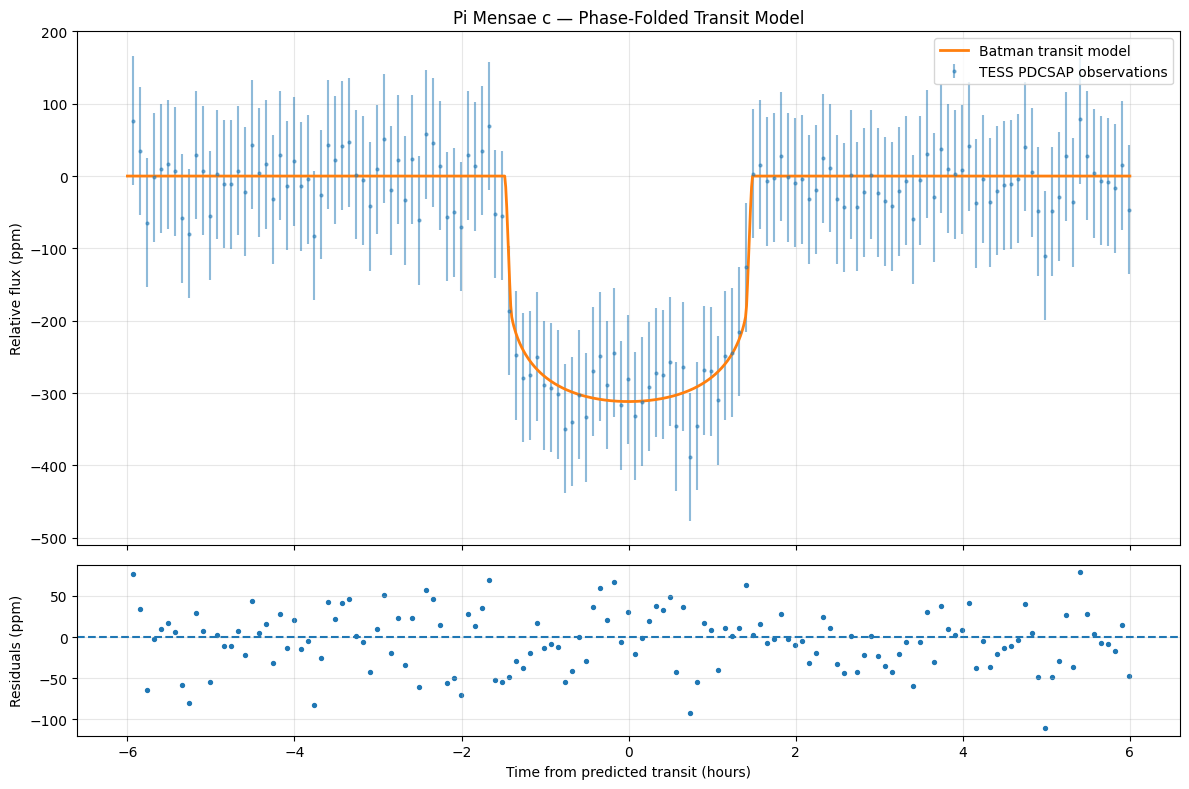

In [62]:
import numpy as np
import matplotlib.pyplot as plt

# Select observations around the transit
mask = np.abs(t) < (6 / 24)

time_plot = t[mask]
flux_plot = f[mask]
error_plot = err[mask]

# Sort observations
order = np.argsort(time_plot)
time_plot = time_plot[order]
flux_plot = flux_plot[order]
error_plot = error_plot[order]

# Generate smooth fitted model
model_time = np.linspace(-0.25, 0.25, 1000)
model_flux = transit_model(model_time, rp_fit)

# Calculate residuals
observed_model = transit_model(time_plot, rp_fit)
residuals = (flux_plot - observed_model) * 1e6

# Create figure
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 8),
    sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}
)

ax1.errorbar(
    time_plot * 24,
    (flux_plot - 1) * 1e6,
    yerr=error_plot * 1e6,
    fmt='.',
    markersize=4,
    alpha=0.5,
    label='TESS PDCSAP observations'
)

ax1.plot(
    model_time * 24,
    (model_flux - 1) * 1e6,
    linewidth=2,
    label='Batman transit model'
)

ax1.set_ylabel('Relative flux (ppm)')
ax1.set_title('Pi Mensae c — Phase-Folded Transit Model')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.scatter(time_plot * 24, residuals, s=8)
ax2.axhline(0, linestyle='--')
ax2.set_xlabel('Time from predicted transit (hours)')
ax2.set_ylabel('Residuals (ppm)')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('Pi_Mensae_Transit_Model.png', dpi=300)
plt.show()

In [41]:
import batman
import numpy as np
from scipy.optimize import curve_fit

# Published parameters
params.t0 = 0.0
params.per = 6.26834
params.a = 13.10
params.inc = 87.31

# Limb-darkening assumptions
params.u = [0.264, 0.309]

# Fit observations
time_fit = binned_research.time.value
flux_fit = binned_research.flux.value
error_fit = binned_research.flux_err.value

def constrained_model(time, rp):

    params.rp = rp

    model = batman.TransitModel(params, time)

    return model.light_curve(params)

popt, pcov = curve_fit(
    constrained_model,
    time_fit,
    flux_fit,
    p0=[0.01721],
    sigma=error_fit,
    absolute_sigma=True,
    bounds=([0.005], [0.04]),
    maxfev=20000
)

fitted_rp = popt[0]
fitted_error = np.sqrt(pcov[0, 0])

print("Constrained radius ratio:", fitted_rp)
print("Estimated uncertainty:", fitted_error)
print("Transit depth (ppm):", fitted_rp**2 * 1e6)

Constrained radius ratio: 0.01515544593011445
Estimated uncertainty: 0.000501820427207068
Transit depth (ppm): 229.6875413406227


`TessTargetPixelFile`'s have many helpful methods and attributes. For example, you can access basic meta data on the target easily:

In [ ]:
tpf.mission

In [ ]:
tpf.targetid  # TESS Input Catalog (TIC) Identifier

In [ ]:
tpf.sector  # TESS Observation Sector

In [ ]:
tpf.camera  # TESS Camera Number

In [ ]:
tpf.ccd  # TESS CCD Number

We might want to plot the data, we can do this with the `plot()` method. You can add the keyword `aperture_mask` to plot an aperture on top of the image. In this case we've used the `pipeline_mask` which is stored in the original .fits file, but you can use any aperture you like.

In [ ]:

tpf.plot(aperture_mask=tpf.pipeline_mask);

If you want to access the original fits file that generated the data you can use the `hdu` attribute of the tpf. This will return an `astropy.io.fits` object, for example

In [ ]:
tpf.hdu

You can access each extension and the data inside it in the same way you'd use [astropy.io.fits](https://docs.astropy.org/en/stable/io/fits/). If you want to access data held in the TPF, such as the time of the observations, you can do that easily by using

In [ ]:
tpf.time

This returns the [Barycentric TESS Julian Date](https://github.com/lightkurve/lightkurve/blob/eb9d3902bf3c2772aade6f4423cfa013394d5af8/src/lightkurve/time.py#L31) (BTJD), the time in units of days counted since [Julian Day](https://en.wikipedia.org/wiki/Julian_day) 2457000.  

You can access the corresponding flux values using

In [ ]:
tpf.flux

Flux is a `numpy.ndarray` with a shape of (TIME x PIXELS x PIXELS). If you want to access just the first frame you can use

In [ ]:
tpf.flux[0]

These values are in units electrons per second.

## Building Light Curves from TPFs

We can use the [to_lightcurve()](https://lightkurve.github.io/lightkurve/reference/api/lightkurve.KeplerTargetPixelFile.to_lightcurve.html) method to turn this TPF into a light curve using *Simple Aperture Photometry*. This will put an aperture on the target, and sum up the flux in all the pixels inside the aperture.

The default for `to_lightcurve()` is to use the mask generated by the TESS pipeline.

In [ ]:
lc = tpf.to_lightcurve()

Now we can use the plot function to take a look at the data.

In [ ]:
lc.errorbar();

This looks pretty good, but maybe we can improve things by creating a new aperture.

In [ ]:
aperture_mask = tpf.create_threshold_mask(threshold=10)

# Plot that aperture
tpf.plot(aperture_mask=aperture_mask);

In [ ]:
lc = tpf.to_lightcurve(aperture_mask=aperture_mask)

In [ ]:
lc.errorbar();

There's a long term trend in this dataset, which we can remove with a simple smoothing filter. You can use the [lc.flatten()](https://lightkurve.github.io/lightkurve/reference/api/lightkurve.LightCurve.flatten.html) method to apply and divide the [Savitzky-Golay smoothing filter](https://en.wikipedia.org/wiki/Savitzky%E2%80%93Golay_filter). Here we'll use a `window_length` of 1001 cadences, which is roughly a 5% of the full length of the light curve.

In [ ]:
# Number of cadences in the full light curve
print(lc.time.shape)

In [ ]:
flat_lc = lc.flatten(window_length=1001)
flat_lc.errorbar();

The light curve looks much flatter. Unfortunately there is a portion of the light curve that is very noisy, due to a jitter in the TESS spacecraft. We can remove this simply by masking the light curve. First we'll select the times that had the jitter.

In [ ]:
# Flag the times that are good quality
mask = (flat_lc.time.value < 1346) | (flat_lc.time.value > 1350)

Then we can just clip those times out.

In [ ]:
masked_lc = flat_lc[mask]
masked_lc.errorbar();

We can use *Lightkurve* to plot these two light curves over each other to see the difference.

In [ ]:
# First define the `matplotlib.pyplot.axes`
ax = flat_lc.errorbar()

# Pass that axis to the next plot
masked_lc.errorbar(ax=ax, label='masked');

This looks much better. Now we might want to clip out some outliers from the light curve. We can do that with a simple lightkurve function [remove_outliers()](https://lightkurve.github.io/lightkurve/reference/api/lightkurve.LightCurve.remove_outliers.html).

In [ ]:
clipped_lc = masked_lc.remove_outliers(sigma=6)
clipped_lc.errorbar();

It's a little hard to see these data because of the plotting style. Let's use a scatter plot instead. We can do this with the [lc.scatter()](https://lightkurve.github.io/lightkurve/reference/api/lightkurve.LightCurve.scatter.html) method. This method works in the same way that [matplotlib.pyplot.scatter](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) works, and takes in the same keyword arguments.

In [ ]:
clipped_lc.scatter(s=0.1);

We can also add errorbars using the [lc.errorbar()](https://lightkurve.github.io/lightkurve/reference/api/lightkurve.LightCurve.errorbar.html) method.

In [ ]:
ax = clipped_lc.scatter(s=0.1)
clipped_lc.errorbar(ax=ax, alpha=0.2);  # alpha determines the transparency

Finally let's use `lightkurve` to fold the data at the exoplanet orbital period and see if we can see the transit.

In [ ]:
folded_lc = clipped_lc.fold(period=6.27, epoch_time=1325.504)
folded_lc.errorbar();

It looks like there's something there, but it's hard to see. Let's bin the light curve to reduce the number of points, but also reduce the uncertainty of those points.

In [ ]:
import astropy.units as u
binned_lc = folded_lc.bin(time_bin_size=5*u.minute)
binned_lc.errorbar();

And now we can see the transit of Pi Men c!

Note that you can actually do all these steps in just a few lines:

In [ ]:
lc = tpf.to_lightcurve(aperture_mask=aperture_mask).flatten(window_length=1001)
lc = lc[(lc.time.value < 1346) | (lc.time.value > 1350)]
lc.remove_outliers(sigma=6).fold(period=6.27, epoch_time=1325.504).bin(time_bin_size=5*u.minute).errorbar();

## Comparing two apertures

In the above tutorial we used our own aperture instead of the pipeline aperture. Let's compare the results from using these two different apertures.

In [ ]:
# Use the default
lc = tpf.to_lightcurve(aperture_mask=tpf.pipeline_mask).flatten(window_length=1001)
lc = lc[(lc.time.value < 1346) | (lc.time.value > 1350)].remove_outliers(6).fold(period=6.27, epoch_time=1325.504).bin(5*u.minute)

# Use a custom aperture
custom_lc = tpf.to_lightcurve(aperture_mask=aperture_mask).flatten(window_length=1001)
custom_lc = custom_lc[(custom_lc.time.value < 1346) | (custom_lc.time.value > 1350)].remove_outliers(6).fold(period=6.27, epoch_time=1325.504).bin(5*u.minute)

In [ ]:
ax = lc.errorbar(label='Default aperture')
custom_lc.errorbar(ax=ax, label='Custom aperture');

The importance of using different aperture masks is clearly visible in the figure above.  Note however that the data archive at MAST also contains lightcurve products which have more advanced systematics removal methods applied.  We will explore those in a future tutorial!